In [1]:
# =====================================================================
from pathlib import Path
import itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use("dark_background")
plt.rcParams.update({
    "figure.facecolor": "#121212",
    "axes.facecolor": "#121212",
    "savefig.facecolor": "#121212",
})
import statsmodels.api as sm
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

warnings.filterwarnings("ignore")
BASE_DIR = next(
    (ruta for ruta in (Path.cwd(), *Path.cwd().parents)
     if (ruta / "base de datos" / "Datos_EMBI.xlsx").is_file()),
    None,
)
if BASE_DIR is None:
    raise FileNotFoundError("No se encontró base de datos/Datos_EMBI.xlsx en la carpeta del proyecto ni en sus carpetas superiores.")
ARCHIVO = BASE_DIR / "base de datos" / "Datos_EMBI.xlsx"
DIA_CORTE = 1                              # día del mes de mar/jun/sep/dic
ORDEN = (0, 1, 2)                          # modelo elegido: ARIMA(0,1,2) (menor AIC)
SALIDA = BASE_DIR / "code" / "resultados_embi"   # misma carpeta de figuras que el script
SALIDA.mkdir(parents=True, exist_ok=True)

In [2]:
# ---------------------------------------------------------------------
raw = pd.read_excel(ARCHIVO, sheet_name="Diarias", header=1)
col_fecha, col_spread = raw.columns[:2]
raw[col_fecha] = pd.to_datetime(raw[col_fecha], errors="coerce")
spread = pd.to_numeric(raw[col_spread], errors="coerce")
validas = raw[col_fecha].notna() & spread.notna()
if not validas.any():
    raise ValueError("No se encontraron filas diarias con fecha y spread válidos.")
if not validas.all():
    print(f"Filas omitidas por fecha o spread inválido/vacío: {(~validas).sum()}")
diaria = pd.Series(spread.loc[validas].to_numpy(),
                   index=pd.DatetimeIndex(raw.loc[validas, col_fecha]),
                   name="spread").sort_index()
cortes, valores = [], []
for anio in range(diaria.index.min().year, diaria.index.max().year + 1):
    for mes in (3, 6, 9, 12):
        corte = pd.Timestamp(anio, mes, DIA_CORTE)
        if diaria.index.min() <= corte <= diaria.index.max():
            cortes.append(corte)
            valores.append(diaria.loc[:corte].iloc[-1])
fechas = pd.DatetimeIndex(cortes)
y = pd.Series(valores, index=fechas, name="spread")
ly = np.log(y)                         # ln(spread)
dly = ly.diff().dropna()               # Δln(spread)
dy = y.diff().dropna()                 # Δ spread
print(f"Diaria: {diaria.index.min():%d/%m/%Y} a {diaria.index.max():%d/%m/%Y}")
print(f"Trimestral (corte día {DIA_CORTE}): {len(y)} obs., {fechas[0]:%d/%m/%Y} a {fechas[-1]:%d/%m/%Y}")
print(f"Fecha convertida a {raw[col_fecha].dtype}; spread original: {raw[col_spread].dtype}")

Diaria: 02/01/1998 a 03/09/2026
Trimestral (corte día 1): 115 obs., 01/03/1998 a 01/09/2026
Fecha convertida a datetime64[us]; spread original: int64



--- Varianza constante, antes y después ---
Nivel    var1=44674.5940 var2=5800.6101 Levene p=0.0000 | ARCH(1) p=0.9115 ARCH(4) p=0.5900
Δ nivel  var1=14721.6773 var2=1503.9906 Levene p=0.0000 | ARCH(1) p=0.9481 ARCH(4) p=0.3188
ln       var1=0.3211 var2=0.0925 Levene p=0.0000 | ARCH(1) p=0.6329 ARCH(4) p=0.1274
Δln      var1=0.0851 var2=0.0235 Levene p=0.0020 | ARCH(1) p=0.5895 ARCH(4) p=0.0812


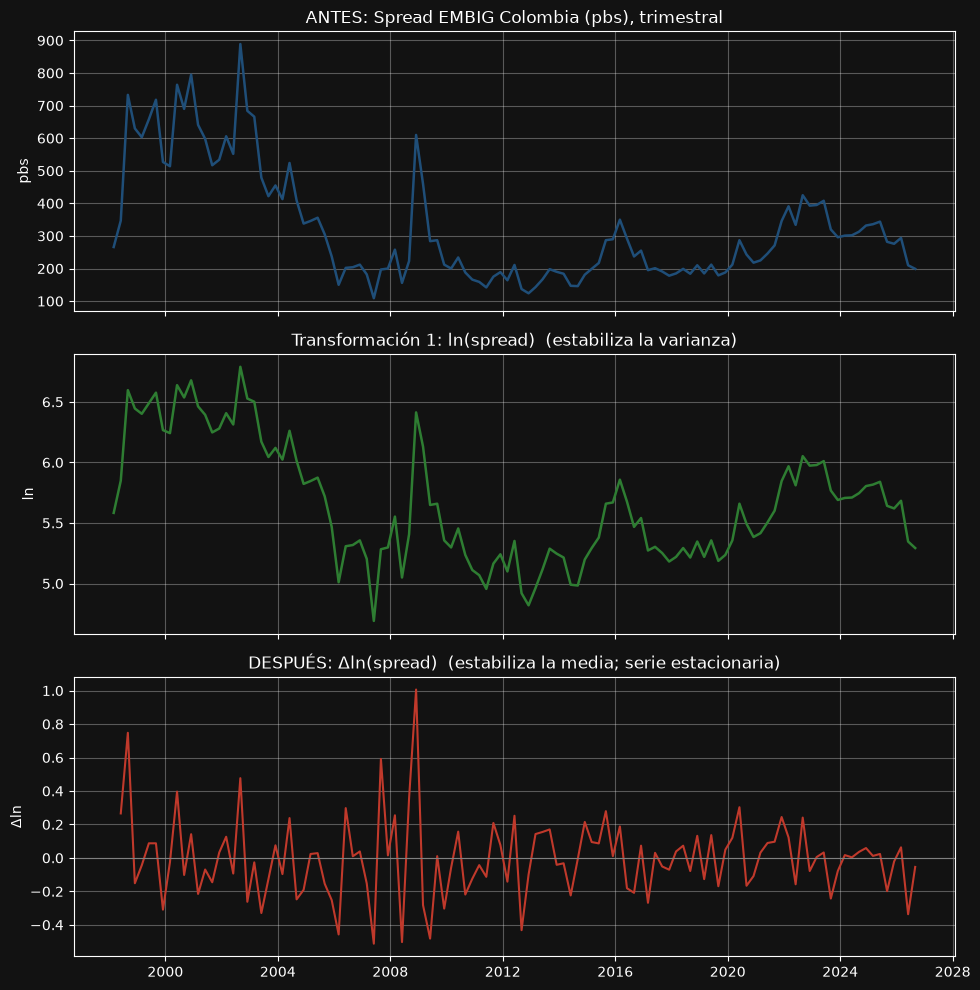

In [3]:
# ---------------------------------------------------------------------
fig, ax = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
ax[0].plot(fechas, y, color="#1F4E78", lw=1.8)
ax[0].set_title("ANTES: Spread EMBIG Colombia (pbs), trimestral"); ax[0].set_ylabel("pbs")
ax[1].plot(fechas, ly, color="#2E7D32", lw=1.8)
ax[1].set_title("Transformación 1: ln(spread)  (estabiliza la varianza)"); ax[1].set_ylabel("ln")
ax[2].plot(fechas[1:], dly, color="#C0392B", lw=1.5); ax[2].axhline(0, color="gray", lw=.8)
ax[2].set_title("DESPUÉS: Δln(spread)  (estabiliza la media; serie estacionaria)"); ax[2].set_ylabel("Δln")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(SALIDA / "fig1_transformacion.png", dpi=150)

# Varianza constante: Levene (mitades) y ARCH-LM sobre residuos AR(1)
def arch_ar1(s, lags):
    s = np.asarray(s)
    res = sm.OLS(s[1:], sm.add_constant(s[:-1])).fit().resid
    return het_arch(res, nlags=lags)[1]

print("\n--- Varianza constante, antes y después ---")
for nombre, s in [("Nivel", y), ("Δ nivel", dy), ("ln", ly), ("Δln", dly)]:
    s = s.reset_index(drop=True); h = len(s) // 2
    print(f"{nombre:8s} var1={s[:h].var():.4f} var2={s[h:].var():.4f} "
          f"Levene p={stats.levene(s[:h], s[h:]).pvalue:.4f} | "
          f"ARCH(1) p={arch_ar1(s,1):.4f} ARCH(4) p={arch_ar1(s,4):.4f}")

In [4]:
# ---------------------------------------------------------------------
# BOX-JENKINS
# Etapa 1. IDENTIFICACIÓN: raíz unitaria y FAC/FACP


=== ETAPA 1: IDENTIFICACIÓN ===
ADF  ln (constante)         est=-2.529 p=0.1086 rezagos=0 crit5%=-2.887
KPSS ln (nivel)             est=0.853 p=0.0100 crit5%=0.463
ADF  ln (const.+tend.)      est=-2.988 p=0.1353 rezagos=0 crit5%=-3.450
KPSS ln (tendencia)         est=0.418 p=0.0100 crit5%=0.146
ADF  Δln (constante)        est=-9.890 p=0.0000 rezagos=1 crit5%=-2.888
KPSS Δln (nivel)            est=0.067 p=0.1000 crit5%=0.463


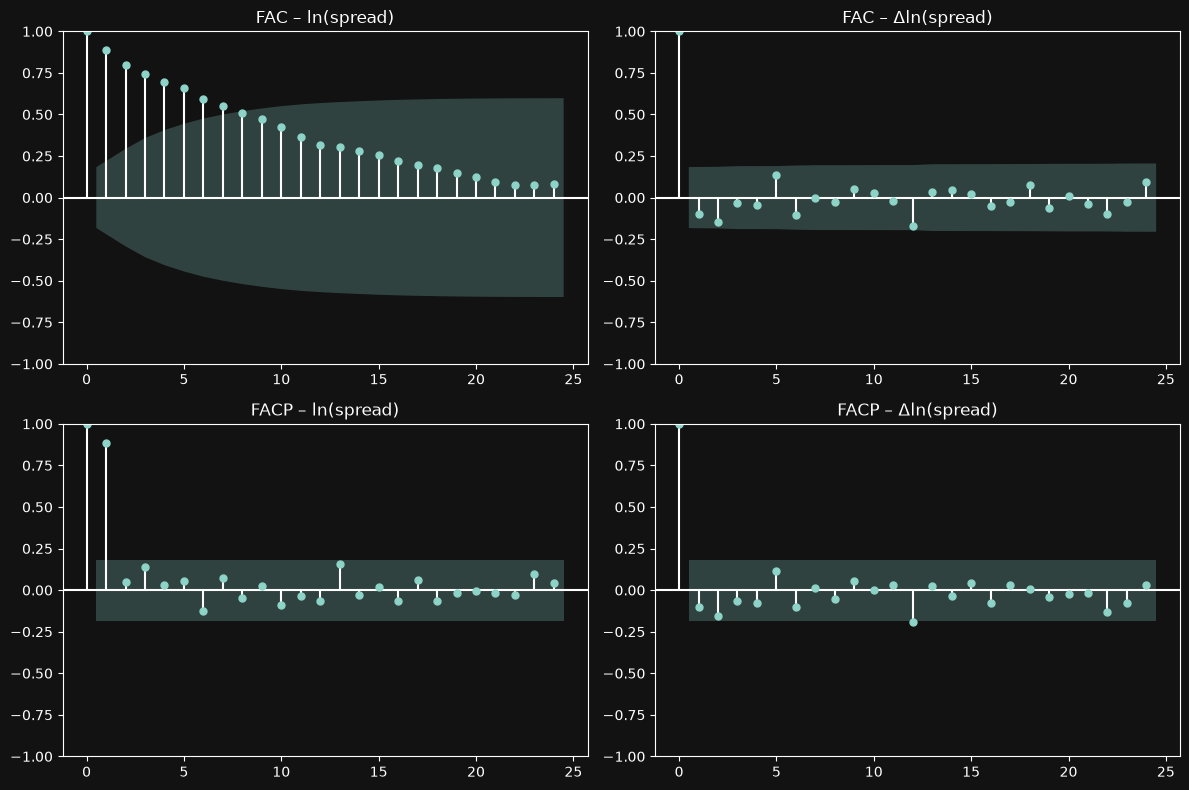

In [5]:
# ---------------------------------------------------------------------
print("\n=== ETAPA 1: IDENTIFICACIÓN ===")
def adf(s, reg, nombre):
    r = adfuller(s, regression=reg, autolag="AIC")
    print(f"ADF  {nombre:22s} est={r[0]:.3f} p={r[1]:.4f} rezagos={r[2]} crit5%={r[4]['5%']:.3f}")
def kp(s, reg, nombre):
    r = kpss(s, regression=reg, nlags=int(4 * (len(s) / 100) ** 0.25))
    print(f"KPSS {nombre:22s} est={r[0]:.3f} p={r[1]:.4f} crit5%={r[3]['5%']}")
adf(ly, "c", "ln (constante)");        kp(ly, "c", "ln (nivel)")
adf(ly, "ct", "ln (const.+tend.)");    kp(ly, "ct", "ln (tendencia)")
adf(dly, "c", "Δln (constante)");      kp(dly, "c", "Δln (nivel)")

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
plot_acf(ly, lags=24, ax=ax[0, 0], title="FAC – ln(spread)")
plot_pacf(ly, lags=24, ax=ax[1, 0], method="ywm", title="FACP – ln(spread)")
plot_acf(dly, lags=24, ax=ax[0, 1], title="FAC – Δln(spread)")
plot_pacf(dly, lags=24, ax=ax[1, 1], method="ywm", title="FACP – Δln(spread)")
plt.tight_layout(); plt.savefig(SALIDA / "fig2_FAC_FACP.png", dpi=150)

In [6]:
# ---------------------------------------------------------------------
# Etapa 1b. ESTACIONALIDAD (s = 4)
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf

print("\n=== ETAPA 1b: ESTACIONALIDAD ===")
trim = dly.index.quarter

# 1) Dummies trimestrales sobre Δln: F conjunta (H0: no hay efecto trimestral)
X = pd.get_dummies(trim, drop_first=True).astype(float)
X.index = dly.index
ols = sm.OLS(dly, sm.add_constant(X)).fit()
print(f"F dummies estacionales: F={ols.fvalue:.2f}  p={ols.f_pvalue:.4f}")

# 2) Kruskal-Wallis por trimestre (no paramétrico)
kw = stats.kruskal(*[dly.values[trim == q] for q in (1, 2, 3, 4)])
print(f"Kruskal-Wallis: p={kw.pvalue:.4f}")

# 3) FAC en rezagos estacionales (4, 8, 12) vs banda ±1.96/√n
a = acf(dly, nlags=12)
print("FAC Δln rezagos 4,8,12:", a[[4, 8, 12]].round(3), "| banda ±", round(1.96 / np.sqrt(len(dly)), 3))

# 4) Fuerza estacional STL: 0 = nada, 1 = muy estacional
stl = STL(ly, period=4, robust=True).fit()
fs = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
print(f"Fuerza estacional (STL, s=4): {fs:.3f}")


=== ETAPA 1b: ESTACIONALIDAD ===
F dummies estacionales: F=0.24  p=0.8659
Kruskal-Wallis: p=0.9440
FAC Δln rezagos 4,8,12: [-0.042 -0.028 -0.17 ] | banda ± 0.184
Fuerza estacional (STL, s=4): 0.055


In [7]:
# ---------------------------------------------------------------------
# Etapa 2. ESTIMACIÓN: comparación por AIC y modelo elegido ARIMA(0,1,2)

In [8]:
# ---------------------------------------------------------------------
print("\n=== ETAPA 2: ESTIMACIÓN ===")
tabla = []
for p, q in itertools.product(range(4), range(4)):
    try:
        mod = ARIMA(ly, order=(p, 1, q)).fit()
        tabla.append((f"ARIMA({p},1,{q})", mod.aic, mod.bic))
    except Exception:
        pass
tabla = pd.DataFrame(tabla, columns=["Modelo", "AIC", "BIC"]).sort_values("AIC")
print("Comparación (referencia, d=1, sin constante):")
print(tabla.head(6).round(2).to_string(index=False))

modelo = ARIMA(ly, order=ORDEN).fit()
print(f"\nModelo elegido: ARIMA{ORDEN}")
print(modelo.summary().tables[1])
print(f"AIC={modelo.aic:.2f}  BIC={modelo.bic:.2f}")
print("Módulo raíz AR:", np.abs(modelo.arroots).round(3), " raíz MA:", np.abs(modelo.maroots).round(3))


=== ETAPA 2: ESTIMACIÓN ===
Comparación (referencia, d=1, sin constante):
      Modelo    AIC   BIC
ARIMA(0,1,2) -10.06 -1.85
ARIMA(1,1,3)  -9.89  3.80
ARIMA(2,1,2)  -9.77  3.91
ARIMA(1,1,1)  -9.21 -1.00
ARIMA(2,1,0)  -9.02 -0.81
ARIMA(0,1,0)  -8.52 -5.78

Modelo elegido: ARIMA(0, 1, 2)
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.1428      0.088     -1.618      0.106      -0.316       0.030
ma.L2         -0.2051      0.095     -2.151      0.031      -0.392      -0.018
sigma2         0.0508      0.005      9.553      0.000       0.040       0.061
AIC=-10.06  BIC=-1.85
Módulo raíz AR: []  raíz MA: [1.887 2.583]


In [9]:
# ---------------------------------------------------------------------
# Etapa 2b. SARIMA vs ARIMA (mismo ly, d=1 → AIC/BIC comparables)
cands = {
    "ARIMA(0,1,2)":            ((0,1,2), (0,0,0,0)),
    "SARIMA(0,1,2)(1,0,0,4)":  ((0,1,2), (1,0,0,4)),
    "SARIMA(0,1,2)(0,0,1,4)":  ((0,1,2), (0,0,1,4)),
    "SARIMA(0,1,2)(0,1,1,4)":  ((0,1,2), (0,1,1,4)),   # diferencia estacional
}
filas = []
for nom, (o, so) in cands.items():
    m = ARIMA(ly, order=o, seasonal_order=so).fit()
    filas.append((nom, m.aic, m.bic))
print(pd.DataFrame(filas, columns=["Modelo", "AIC", "BIC"]).sort_values("AIC").round(2).to_string(index=False))

                Modelo    AIC   BIC
          ARIMA(0,1,2) -10.06 -1.85
SARIMA(0,1,2)(0,0,1,4)  -8.37  2.58
SARIMA(0,1,2)(1,0,0,4)  -8.33  2.61
SARIMA(0,1,2)(0,1,1,4)   9.31 20.11


In [10]:
# ---------------------------------------------------------------------
# Etapa 3. DIAGNÓSTICO de residuos (se descarta el primero por la diferenciación)


=== ETAPA 3: DIAGNÓSTICO ===
Ljung-Box p (4,8,12): [0.825, 0.714, 0.642]
ARCH-LM(4) p: 0.501
Jarque-Bera p: 2.81e-13 | asimetría=0.89 curtosis=6.01


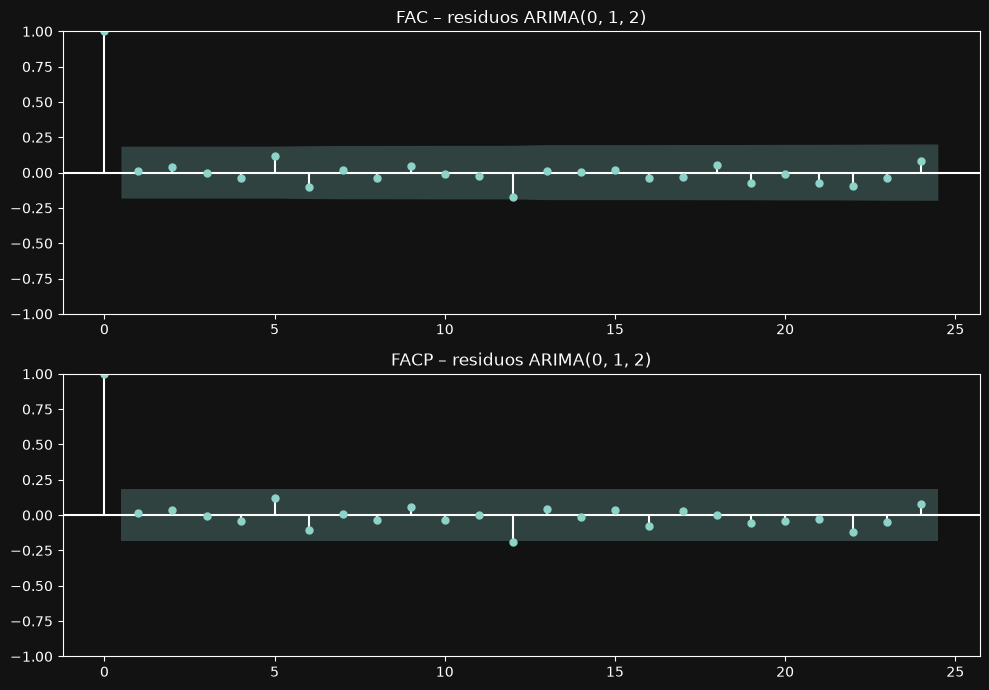

In [11]:
# ---------------------------------------------------------------------
print("\n=== ETAPA 3: DIAGNÓSTICO ===")
res = modelo.resid[1:]
lb = acorr_ljungbox(res, lags=[4, 8, 12], model_df=ORDEN[0] + ORDEN[2])
print("Ljung-Box p (4,8,12):", lb["lb_pvalue"].round(3).tolist())
print("ARCH-LM(4) p:", round(het_arch(res, nlags=4)[1], 3))
jb = stats.jarque_bera(res)
print(f"Jarque-Bera p: {jb[1]:.2e} | asimetría={stats.skew(res):.2f} curtosis={stats.kurtosis(res, fisher=False):.2f}")

fig, ax = plt.subplots(2, 1, figsize=(10, 7))
plot_acf(res, lags=24, ax=ax[0], title=f"FAC – residuos ARIMA{ORDEN}")
plot_pacf(res, lags=24, ax=ax[1], method="ywm", title=f"FACP – residuos ARIMA{ORDEN}")
plt.tight_layout(); plt.savefig(SALIDA / "fig3_residuos.png", dpi=150)

In [12]:
# ---------------------------------------------------------------------
# Etapa 4. PRONÓSTICO a 2 trimestres (IC 95% y 90%), en pbs


=== ETAPA 4: PRONÓSTICO ===
     Fecha  Punto  IC95_inf  IC95_sup  IC90_inf  IC90_sup
01/12/2026  216.5     139.2     336.8     149.4     313.7
01/03/2027  220.9     123.5     395.3     135.6     360.0
Último dato observado (01/09/2026): 199 pbs


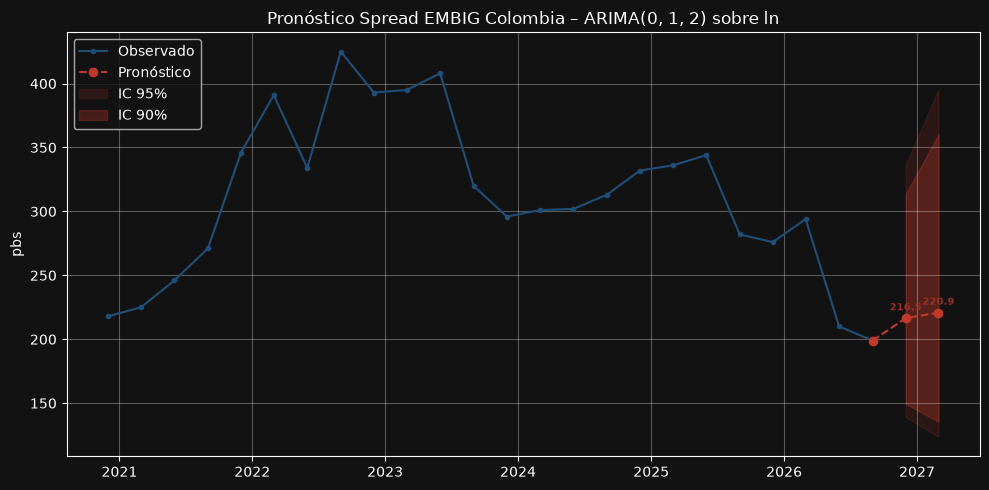

In [13]:
# ---------------------------------------------------------------------
print("\n=== ETAPA 4: PRONÓSTICO ===")
fc = modelo.get_forecast(2)
punto = np.exp(fc.predicted_mean.values)
ic95 = np.exp(fc.conf_int(alpha=0.05).values)
ic90 = np.exp(fc.conf_int(alpha=0.10).values)
fut = [fechas[-1] + pd.DateOffset(months=3), fechas[-1] + pd.DateOffset(months=6)]
pron = pd.DataFrame({"Fecha": [f"{f:%d/%m/%Y}" for f in fut], "Punto": punto,
                     "IC95_inf": ic95[:, 0], "IC95_sup": ic95[:, 1],
                     "IC90_inf": ic90[:, 0], "IC90_sup": ic90[:, 1]})
print(pron.round(1).to_string(index=False))
print(f"Último dato observado ({fechas[-1]:%d/%m/%Y}): {y.iloc[-1]:.0f} pbs")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(fechas[-24:], y[-24:], marker="o", ms=3, color="#1F4E78", label="Observado")
ax.plot([fechas[-1], *fut], [y.iloc[-1], *punto], "--o", color="#C0392B", label="Pronóstico")
ax.fill_between(fut, ic95[:, 0], ic95[:, 1], color="#C0392B", alpha=.15, label="IC 95%")
ax.fill_between(fut, ic90[:, 0], ic90[:, 1], color="#C0392B", alpha=.30, label="IC 90%")
for fecha, valor in zip(fut, punto):
    ax.annotate(f"{valor:.1f}", xy=(fecha, valor), xytext=(0, 4),
                textcoords="offset points", ha="center", va="bottom",
                color="#9C2F25", fontsize=7, fontweight="bold", zorder=10)
ax.set_title(f"Pronóstico Spread EMBIG Colombia – ARIMA{ORDEN} sobre ln"); ax.set_ylabel("pbs")
ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(SALIDA / "fig4_pronostico.png", dpi=150)
plt.show()

# Etapa 5 (adición): intervalos de pronóstico ajustados por volatilidad

**Qué se añade:** solo cambia el *ancho* de los intervalos de confianza de la Etapa 4. El modelo (ARIMA(0,1,2) sobre ln del spread), sus coeficientes y el pronóstico puntual **no se modifican**. Las celdas anteriores quedan intactas.

**Por qué:** los errores del modelo fueron mucho más grandes antes de la crisis de 2008-2009 que después (Levene sobre Δln: p = 0.002). La Etapa 4 usa un único tamaño de error para toda la historia (σ ≈ 0.225), inflado por la época volátil, y por eso sus intervalos son anchos.

**Cómo:** (1) se detecta el corte donde cambia la volatilidad de los residuos (o se fija a mano con `CORTE_VOL`); (2) se calcula σ solo con la época reciente; (3) se reescala el error estándar del pronóstico por σ_reciente / σ_total y se recalculan los intervalos.

**Cuidado:** el rango ajustado supone que no habrá una nueva crisis. Presentarlo junto al original, que queda como escenario conservador.


=== ETAPA 5: AJUSTE DE VOLATILIDAD POR ÉPOCAS ===
Corte de volatilidad: 01/03/2009 | σ antes=0.308 σ después=0.161 | Levene p=0.0017
Época reciente: n=71 | asimetría=-0.13 curtosis=2.93 | Jarque-Bera p=0.905
σ total=0.225 | σ reciente=0.161 | factor de ajuste=0.72
     Fecha  Punto IC95_orig IC95_ajust IC90_orig IC90_ajust  Ancho95_orig  Ancho95_ajust
01/12/2026  216.5   139-337    158-297   149-314    166-282         197.6          139.1
01/03/2027  220.9   123-395    146-335   136-360    156-313         271.8          189.2


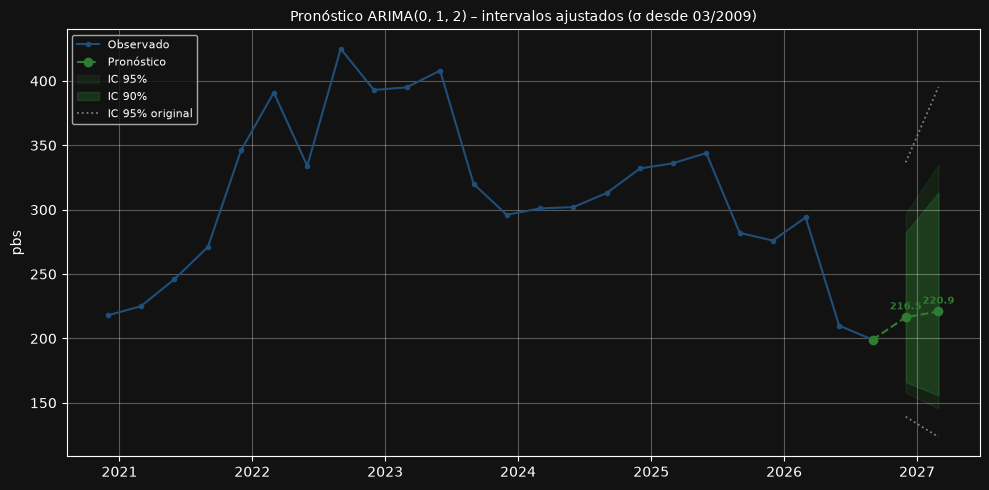

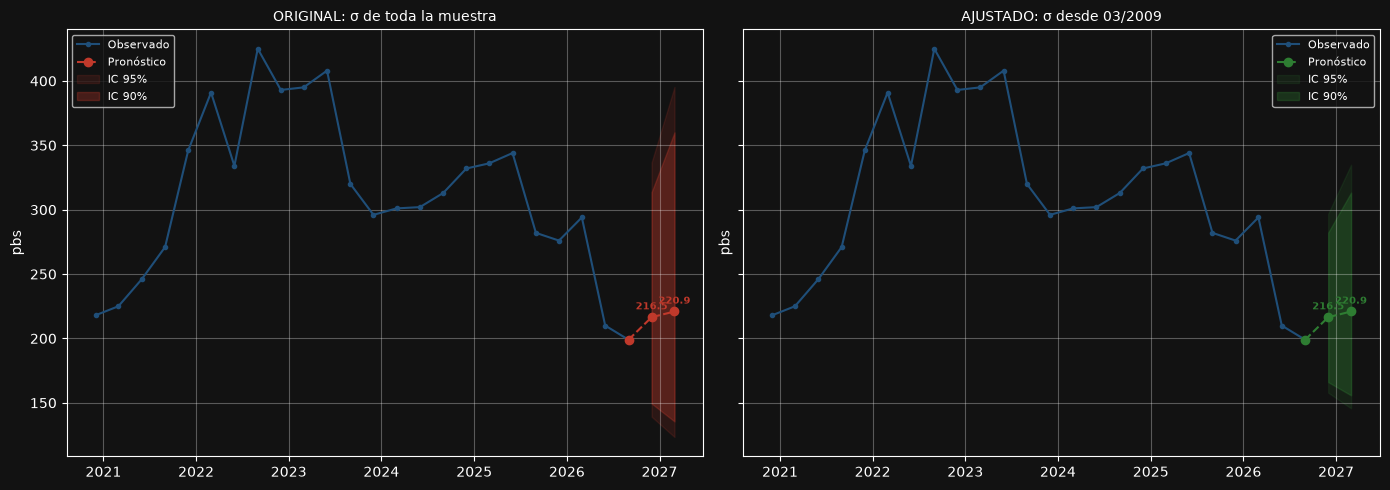

In [14]:
# ---------------------------------------------------------------------
# ETAPA 5 (adición). Intervalos ajustados por volatilidad por épocas
# No modifica el modelo ni el pronóstico puntual: solo reescala el ancho del IC.
CORTE_VOL = None          # None = detectar automáticamente; o fijar, p.ej. pd.Timestamp(2009, 3, 1)
MIN_OBS = 25              # mínimo de residuos a cada lado del corte al buscarlo

print("\n=== ETAPA 5: AJUSTE DE VOLATILIDAD POR ÉPOCAS ===")
res_s = pd.Series(np.asarray(modelo.resid)[1:], index=fechas[1:])   # se descarta el 1.º residuo

# 1) Corte: donde la diferencia de varianza entre antes y después es más significativa (Levene)
if CORTE_VOL is None:
    cand = [(res_s.index[k], stats.levene(res_s.iloc[:k], res_s.iloc[k:]).pvalue)
            for k in range(MIN_OBS, len(res_s) - MIN_OBS)]
    CORTE_VOL = min(cand, key=lambda t: t[1])[0]
ant, rec = res_s[res_s.index < CORTE_VOL], res_s[res_s.index >= CORTE_VOL]
lev = stats.levene(ant, rec).pvalue
print(f"Corte de volatilidad: {CORTE_VOL:%d/%m/%Y} | σ antes={ant.std():.3f} σ después={rec.std():.3f} "
      f"| Levene p={lev:.4f}")
print(f"Época reciente: n={len(rec)} | asimetría={stats.skew(rec):.2f} "
      f"curtosis={stats.kurtosis(rec, fisher=False):.2f} | Jarque-Bera p={stats.jarque_bera(rec)[1]:.3f}")

# 2) σ total (la del modelo) vs σ de la época reciente
sigma_tot = np.sqrt(modelo.params["sigma2"])
sigma_rec = rec.std()
factor = sigma_rec / sigma_tot
print(f"σ total={sigma_tot:.3f} | σ reciente={sigma_rec:.3f} | factor de ajuste={factor:.2f}")

# 3) Intervalos ajustados: mismo punto, error estándar reescalado
mu = np.asarray(fc.predicted_mean)
se = np.asarray(fc.se_mean) * factor
def ic_aj(alpha):
    z = stats.norm.ppf(1 - alpha / 2)
    return np.exp(np.column_stack([mu - z * se, mu + z * se]))
ic95_aj, ic90_aj = ic_aj(0.05), ic_aj(0.10)

comp = pd.DataFrame({
    "Fecha": [f"{f:%d/%m/%Y}" for f in fut], "Punto": punto,
    "IC95_orig": [f"{a:.0f}-{b:.0f}" for a, b in ic95],
    "IC95_ajust": [f"{a:.0f}-{b:.0f}" for a, b in ic95_aj],
    "IC90_orig": [f"{a:.0f}-{b:.0f}" for a, b in ic90],
    "IC90_ajust": [f"{a:.0f}-{b:.0f}" for a, b in ic90_aj],
    "Ancho95_orig": ic95[:, 1] - ic95[:, 0], "Ancho95_ajust": ic95_aj[:, 1] - ic95_aj[:, 0]})
print(comp.round(1).to_string(index=False))

# 4) Figura 5: pronóstico con rango ajustado (línea gris = IC95 original) y figura 6: contraste
def panel(ax, a95, a90, color, titulo, ref95=None):
    ax.plot(fechas[-24:], y[-24:], marker="o", ms=3, color="#1F4E78", label="Observado")
    ax.plot([fechas[-1], *fut], [y.iloc[-1], *punto], "--o", color=color, label="Pronóstico")
    ax.fill_between(fut, a95[:, 0], a95[:, 1], color=color, alpha=.15, label="IC 95%")
    ax.fill_between(fut, a90[:, 0], a90[:, 1], color=color, alpha=.30, label="IC 90%")
    if ref95 is not None:
        ax.plot(fut, ref95[:, 0], ":", color="gray", lw=1.3, label="IC 95% original")
        ax.plot(fut, ref95[:, 1], ":", color="gray", lw=1.3)
    for fecha, valor in zip(fut, punto):
        ax.annotate(f"{valor:.1f}", xy=(fecha, valor), xytext=(0, 4), textcoords="offset points",
                    ha="center", va="bottom", color=color, fontsize=7, fontweight="bold", zorder=10)
    ax.set_title(titulo, fontsize=10); ax.set_ylabel("pbs"); ax.grid(alpha=.3); ax.legend(fontsize=8)

fig, ax = plt.subplots(figsize=(10, 5))
panel(ax, ic95_aj, ic90_aj, "#2E7D32",
      f"Pronóstico ARIMA{ORDEN} – intervalos ajustados (σ desde {CORTE_VOL:%m/%Y})", ref95=ic95)
plt.tight_layout(); plt.savefig(SALIDA / "fig5_pronostico_ajustado.png", dpi=150)

fig, axs = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
panel(axs[0], ic95, ic90, "#C0392B", "ORIGINAL: σ de toda la muestra")
panel(axs[1], ic95_aj, ic90_aj, "#2E7D32", f"AJUSTADO: σ desde {CORTE_VOL:%m/%Y}")
plt.tight_layout(); plt.savefig(SALIDA / "fig6_comparacion_original_vs_ajustado.png", dpi=150)
plt.show()


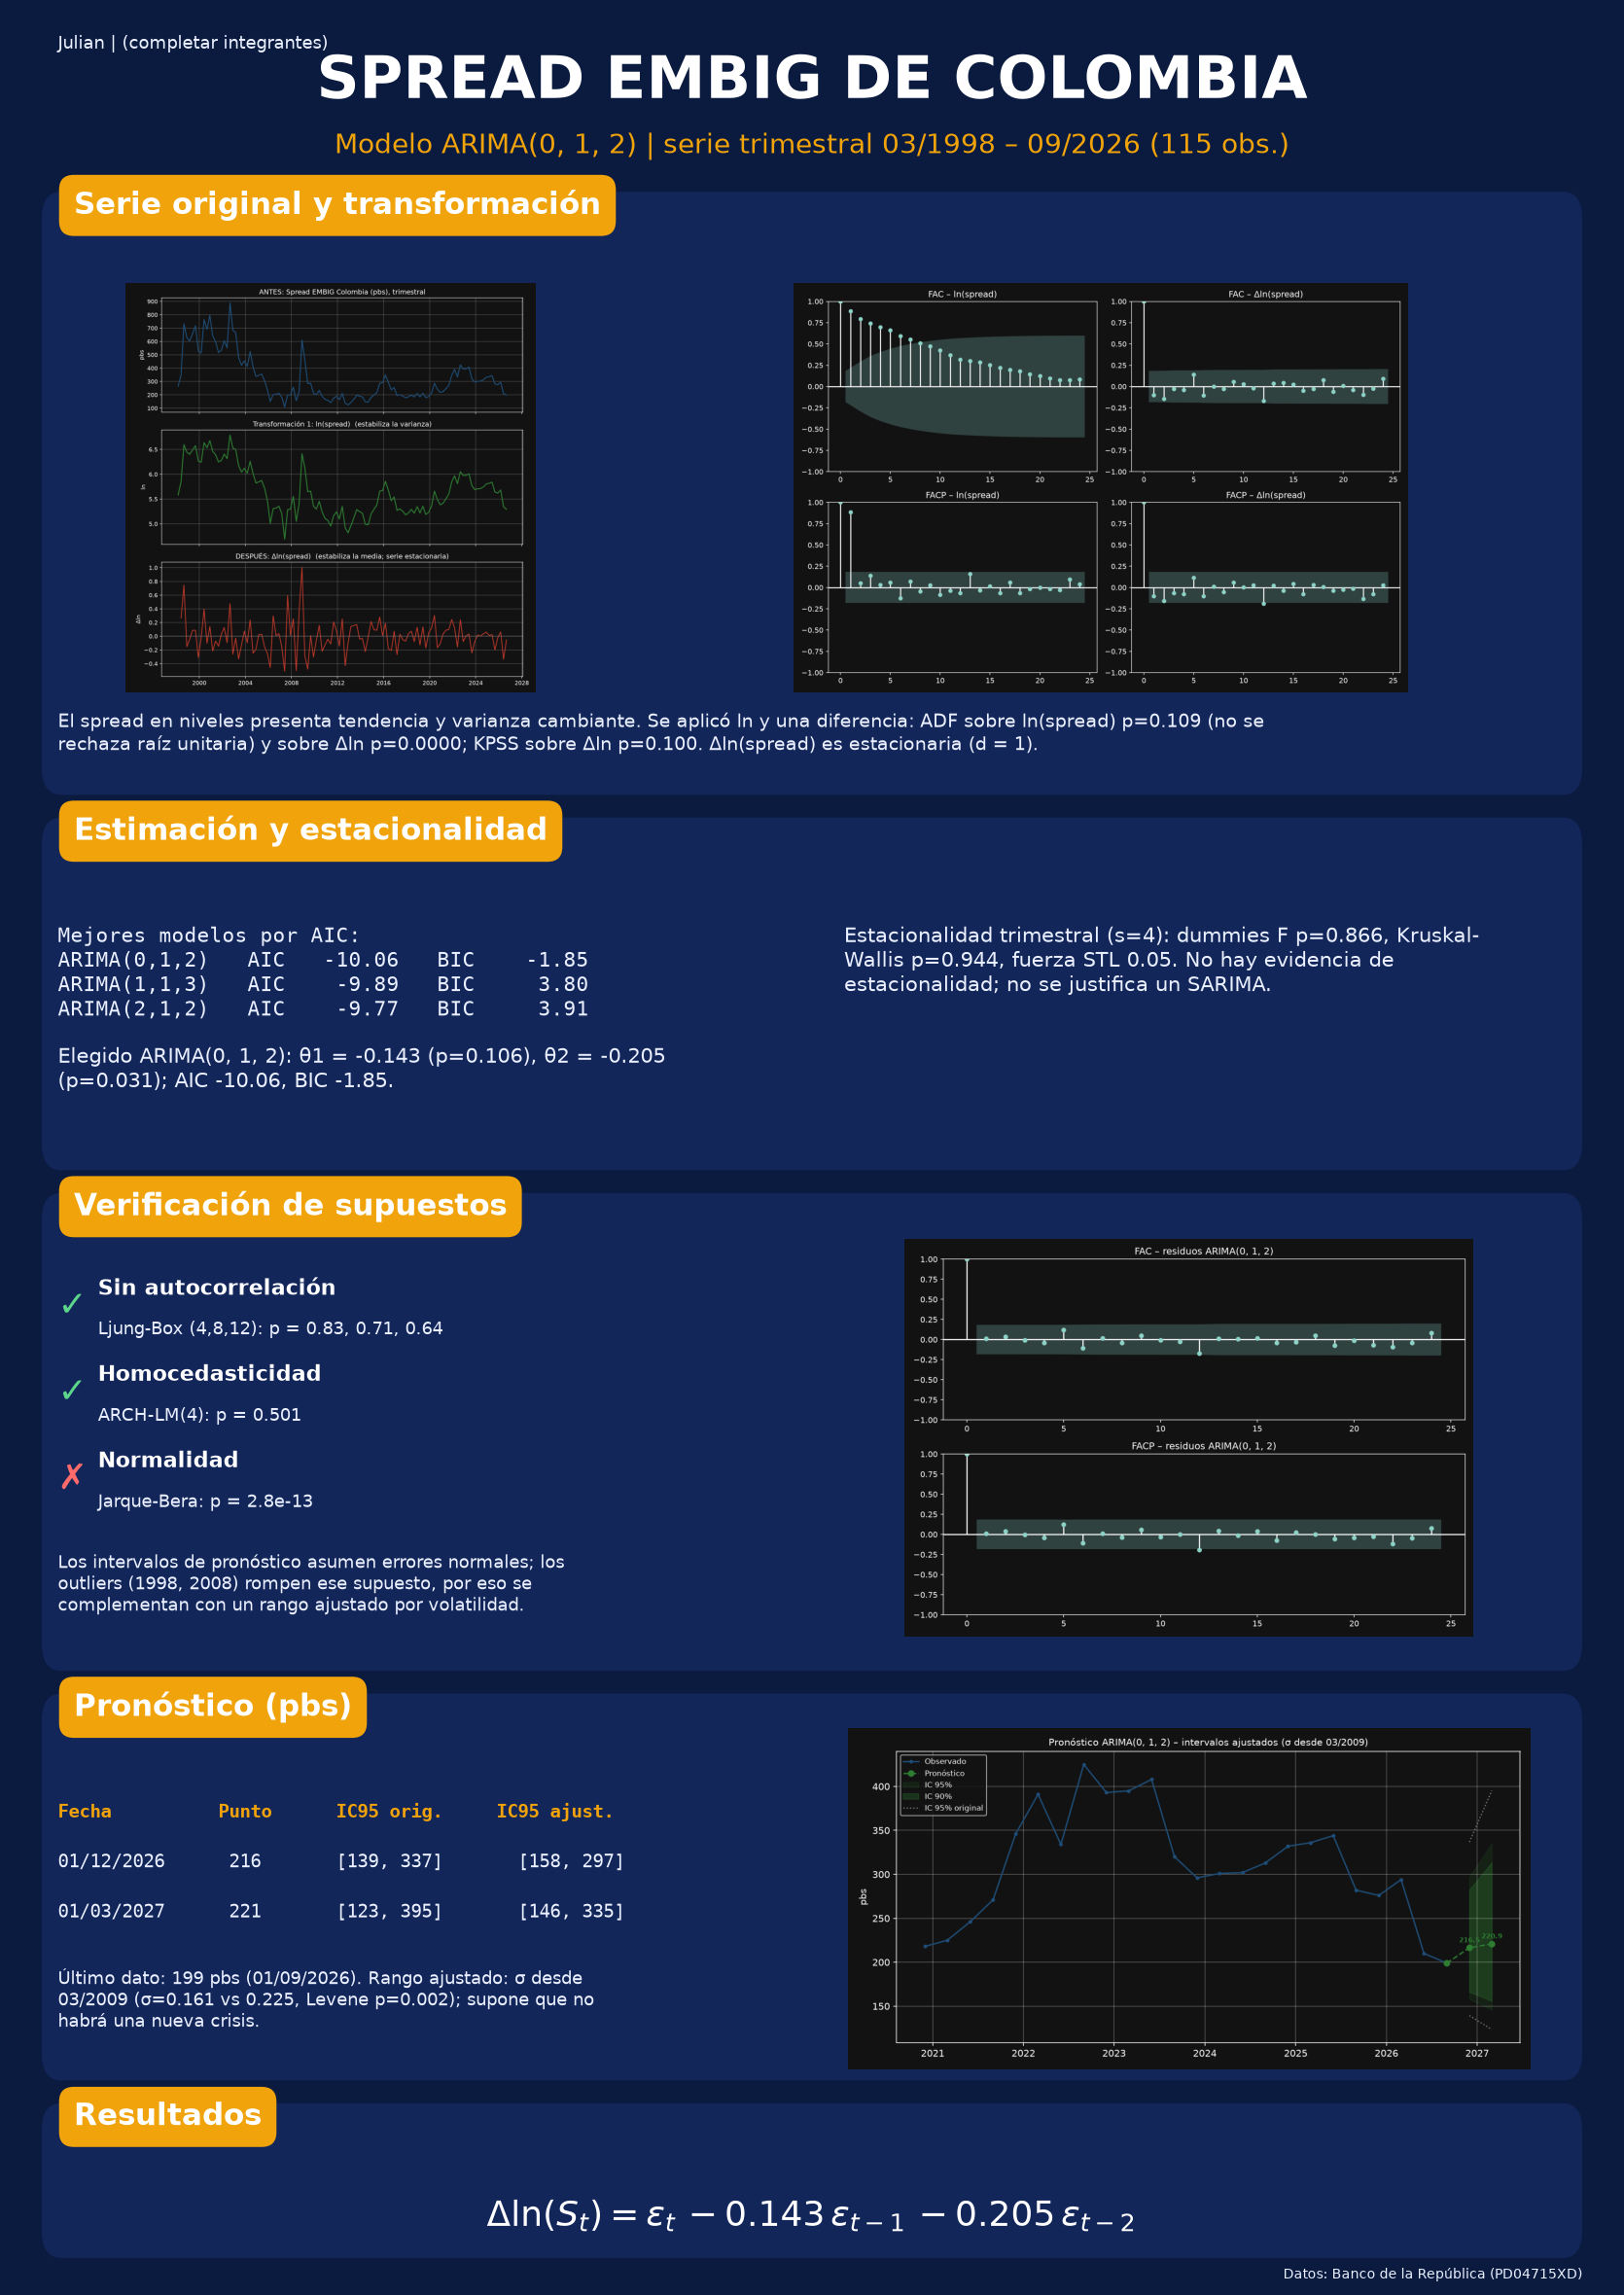

In [ ]:
# ---------------------------------------------------------------------
# ETAPA 6. PÓSTER (PDF) armado con las variables y figuras de las etapas anteriores
import textwrap
from matplotlib.patches import FancyBboxPatch

AUTORES = ""  # <-- editar
BG, CARD, ACC, TXT, OK, KO = "#0B1B3F", "#13265A", "#F0A30A", "#EAF0FF", "#5CD68A", "#FF6B6B"

# --- cifras ---
n_obs = len(y)
adf_ly = adfuller(ly, regression="c", autolag="AIC")[1]
adf_dly = adfuller(dly, regression="c", autolag="AIC")[1]
kpss_dly = kpss(dly, regression="c", nlags=int(4 * (len(dly) / 100) ** 0.25))[1]
res_ = np.asarray(modelo.resid)[1:]
lb_p = acorr_ljungbox(res_, lags=[4, 8, 12], model_df=ORDEN[0] + ORDEN[2])["lb_pvalue"].to_numpy()
arch_p = het_arch(res_, nlags=4)[1]
jb_p = stats.jarque_bera(res_)[1]
th1, th2 = modelo.params["ma.L1"], modelo.params["ma.L2"]
p1, p2 = modelo.pvalues["ma.L1"], modelo.pvalues["ma.L2"]
top = tabla.head(3).reset_index(drop=True)
pF, pK = ols.f_pvalue, kw.pvalue
hay_est = min(pF, pK) < 0.05

def marca(ok): return ("✓", OK) if ok else ("✗", KO)

fig = plt.figure(figsize=(16.5, 23.4), facecolor=BG)
bg = fig.add_axes([0, 0, 1, 1]); bg.set_xlim(0, 1); bg.set_ylim(0, 1); bg.axis("off")

def card(x0, y0, w, h, titulo):
    bg.add_patch(FancyBboxPatch((x0, y0), w, h, boxstyle="round,pad=0,rounding_size=0.012",
                                fc=CARD, ec="none"))
    bg.text(x0 + 0.02, y0 + h - 0.006, titulo, color="white", fontsize=22, fontweight="bold",
            va="center", ha="left", bbox=dict(boxstyle="round,pad=0.5", fc=ACC, ec="none"))

def texto(x, yv, s, w=60, size=15, color=TXT, **kw):
    bg.text(x, yv, textwrap.fill(s, w), color=color, fontsize=size, va="top", ha="left", **kw)

def imagen(rect, nombre):
    ax = fig.add_axes(rect); ax.imshow(plt.imread(SALIDA / nombre)); ax.axis("off")

# --- encabezado ---
bg.text(0.5, 0.968, "SPREAD EMBIG DE COLOMBIA", color="white", fontsize=44, fontweight="bold", ha="center", va="center")
bg.text(0.5, 0.940, f"Modelo ARIMA{ORDEN} | serie trimestral {fechas[0]:%m/%Y} – {fechas[-1]:%m/%Y} ({n_obs} obs.)",
        color=ACC, fontsize=20, ha="center", va="center")
bg.text(0.03, 0.985, AUTORES, color=TXT, fontsize=13, ha="left", va="center")

# --- 1. serie original y transformación ---
card(0.02, 0.655, 0.96, 0.265, "Serie original y transformación")
imagen([0.03, 0.700, 0.34, 0.180], "fig1_transformacion.png")
imagen([0.39, 0.700, 0.58, 0.180], "fig2_FAC_FACP.png")
texto(0.03, 0.692,
      f"El spread en niveles presenta tendencia y varianza cambiante. Se aplicó ln y una diferencia: ADF sobre ln(spread) "
      f"p={adf_ly:.3f} (no se rechaza raíz unitaria) y sobre Δln p={adf_dly:.4f}; KPSS sobre Δln p={kpss_dly:.3f}. "
      f"Δln(spread) es estacionaria (d = 1).", w=130, size=14)

# --- 2. estimación y estacionalidad ---
card(0.02, 0.490, 0.96, 0.155, "Estimación y estacionalidad")
filas = "\n".join(f"{r.Modelo:14s} AIC {r.AIC:8.2f}   BIC {r.BIC:8.2f}" for r in top.itertuples())
bg.text(0.03, 0.598, "Mejores modelos por AIC:\n" + filas, color=TXT, fontsize=15, family="monospace", va="top")
texto(0.03, 0.545,
      f"Elegido ARIMA{ORDEN}: θ1 = {th1:.3f} (p={p1:.3f}), θ2 = {th2:.3f} (p={p2:.3f}); AIC {modelo.aic:.2f}, BIC {modelo.bic:.2f}.",
      w=60, size=15)
est_txt = (f"Estacionalidad trimestral (s=4): dummies F p={pF:.3f}, Kruskal-Wallis p={pK:.3f}, fuerza STL {fs:.2f}. "
           + ("Hay evidencia de patrón estacional; se contrastó SARIMA." if hay_est else
              "No hay evidencia de estacionalidad; no se justifica un SARIMA."))
texto(0.52, 0.598, est_txt, w=62, size=15)

# --- 3. verificación de supuestos ---
card(0.02, 0.270, 0.96, 0.210, "Verificación de supuestos")
tests = [("Sin autocorrelación", f"Ljung-Box (4,8,12): p = {', '.join(f'{v:.2f}' for v in lb_p)}", lb_p.min() > 0.05),
         ("Homocedasticidad",    f"ARCH-LM(4): p = {arch_p:.3f}", arch_p > 0.05),
         ("Normalidad",          f"Jarque-Bera: p = {jb_p:.1e}", jb_p > 0.05)]
for i, (nom, det, ok) in enumerate(tests):
    m, c = marca(ok); yy = 0.430 - i * 0.038
    bg.text(0.03, yy, m, color=c, fontsize=26, fontweight="bold", va="center")
    bg.text(0.055, yy + 0.008, nom, color="white", fontsize=16, fontweight="bold", va="center")
    bg.text(0.055, yy - 0.010, det, color=TXT, fontsize=13, va="center")
texto(0.03, 0.322,
      "Los intervalos de pronóstico asumen errores normales; los outliers (1998, 2008) rompen ese supuesto, "
      "por eso se complementan con un rango ajustado por volatilidad.", w=62, size=13)
imagen([0.50, 0.285, 0.47, 0.175], "fig3_residuos.png")

# --- 4. pronóstico ---
card(0.02, 0.090, 0.96, 0.170, "Pronóstico (pbs)")
bg.text(0.03, 0.212, f"{'Fecha':12s}{'Punto':>8s}{'IC95 orig.':>16s}{'IC95 ajust.':>16s}", color=ACC,
        fontsize=14, family="monospace", va="top", fontweight="bold")
for i in range(len(punto)):
    bg.text(0.03, 0.190 - i * 0.022,
            f"{fut[i]:%d/%m/%Y}  {punto[i]:7.0f}  {f'[{ic95[i,0]:.0f}, {ic95[i,1]:.0f}]':>15s}  {f'[{ic95_aj[i,0]:.0f}, {ic95_aj[i,1]:.0f}]':>15s}",
            color=TXT, fontsize=14, family="monospace", va="top")
texto(0.03, 0.140,
      f"Último dato: {y.iloc[-1]:.0f} pbs ({fechas[-1]:%d/%m/%Y}). Rango ajustado: σ desde {CORTE_VOL:%m/%Y} "
      f"(σ={sigma_rec:.3f} vs {sigma_tot:.3f}, Levene p={lev:.3f}); supone que no habrá una nueva crisis.",
      w=62, size=13)
imagen([0.50, 0.095, 0.47, 0.150], "fig5_pronostico_ajustado.png")

# --- 5. resultados ---
card(0.02, 0.012, 0.96, 0.068, "Resultados")
bg.text(0.5, 0.030, rf"$\Delta\ln(S_t)=\varepsilon_t\,{th1:+.3f}\,\varepsilon_{{t-1}}\,{th2:+.3f}\,\varepsilon_{{t-2}}$",
        color="white", fontsize=26, ha="center", va="center")
bg.text(0.98, 0.003, "Datos: Banco de la República (PD04715XD)", color=TXT, fontsize=10, ha="right")

fig.savefig(SALIDA / "poster_embig.pdf", facecolor=BG)
fig.savefig(SALIDA / "poster_embig_preview.png", dpi=60, facecolor=BG)
plt.show()